<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-10/lab-059-continuous-angles.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 059. Continuous-angle compilation of a W target
We prepare $|W_2\rangle=(|01\rangle+|10\rangle)/\sqrt2$ from $|00\rangle$. This entangled target is the two-qubit member of the W family. For two qubits it is the Bell state $|\Psi^+\rangle$, and the GHZ and W families of Lab 057 differ only from three qubits on. A circuit has three layers of two $\hat R_y$ rotations, with an entangling operation on the bond after each of the first two layers. The allowed bond choices are no gate, CNOT and CZ. Every episode has the same depth and its reward is final fidelity $F=|\langle W_2|\psi\rangle|^2$, with discount one and no gate cost. We call a circuit successful when $F>0.99$, the threshold used in Lab 058.

We learn independent Gaussian angles and categorical gates conditioned on layer index. This is a deliberately small time-dependent policy, with directly trained means, log widths and gate preferences. It has no state-reading network. Lab 055 contains the full state-dependent neural study. Run in order with NumPy, SciPy and Matplotlib.

The simulator supplies exact terminal fidelity, or a sampled estimate when shots are enabled. REINFORCE uses sampled returns and log probabilities. The reference uses exact parameter-shift gradients on a fixed CNOT template.

## Operations and scores

Each rotation is $\hat R_y(a)=e^{-ia\hat Y/2}=\begin{pmatrix}\cos\frac a2&-\sin\frac a2\\ \sin\frac a2&\cos\frac a2\end{pmatrix}$, a real rotation of one qubit. The bond choices are the identity, the CNOT of Lab 057 and the controlled-Z gate $\mathrm{CZ}=\mathrm{diag}(1,1,1,-1)$, which multiplies $|11\rangle$ by $-1$. Only CNOT and CZ can create entanglement.

The reference optimiser uses the parameter-shift rule. The generator $\hat Y/2$ of $\hat R_y$ has eigenvalues $\pm1/2$, so the fidelity depends on one angle as $A+B\cos a+C\sin a$. For such a function the derivative is exactly $\partial_aF=[F(a+\pi/2)-F(a-\pi/2)]/2$, and each derivative costs two fidelity evaluations.

The policy samples each angle as $a=\mu+\sigma\epsilon$ with standard normal $\epsilon$ and $\nu=\log\sigma$. Differentiating $\log\pi=-\nu-(a-\mu)^2/(2\sigma^2)-\tfrac12\log2\pi$ at the fixed sample gives the scores $\partial_\mu\log\pi=\epsilon/\sigma$ and $\partial_\nu\log\pi=\epsilon^2-1$. The first cell defines the circuit and checks the parameter-shift gradient and these scores against finite differences.

In [1]:
import time,json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
OUT=Path('classroom_results');OUT.mkdir(exist_ok=True)
started=time.perf_counter()
LAYERS,N=3,2
CX=np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]])
CZ=np.diag([1,1,1,-1]);ENT=np.array([np.eye(4),CX,CZ])
target=np.array([0,1,1,0])/np.sqrt(2)
def circuit(angles,types):
    angles=np.asarray(angles);b=len(angles)
    psi=np.zeros((b,2,2));psi[:,0,0]=1
    for t in range(LAYERS):
        for q in range(N):
            a=angles[:,t,q];co=np.cos(a/2);si=np.sin(a/2)
            R=np.stack([co,-si,si,co],axis=-1).reshape(b,2,2)
            psi=np.einsum('bij,bjk->bik',R,psi) if q==0 else np.einsum('bik,bjk->bij',psi,R)
        if t<LAYERS-1:
            psi=np.einsum('bij,bj->bi',ENT[types[:,t]],psi.reshape(b,4)).reshape(b,2,2)
    assert np.allclose(np.sum(psi**2,axis=(1,2)),1)
    return np.clip((psi.reshape(b,4)@target)**2,0,1)
def softmax(z):
    e=np.exp(z-z.max(-1,keepdims=True));return e/e.sum(-1,keepdims=True)
def template_f(x):return circuit(x.reshape(1,LAYERS,N),np.ones((1,LAYERS-1),int))[0]
def shift_gradient(x):
    shifts=np.eye(x.size)*np.pi/2
    return np.array([(template_f(x+d)-template_f(x-d))/2 for d in shifts])
x=np.random.default_rng(1).normal(size=LAYERS*N);d=1e-6
fd=np.array([(template_f(x+np.eye(x.size)[k]*d)-template_f(x-np.eye(x.size)[k]*d))/(2*d) for k in range(x.size)])
assert np.allclose(fd,shift_gradient(x),atol=1e-8)
print('Parameter-shift gradient checked against finite differences')
# Scores differentiate the log density at a fixed sampled action.
fixed_action,mean,log_width=.4,-.2,np.log(.7)
def log_density(mean,log_width):
    return -log_width-(fixed_action-mean)**2/(2*np.exp(2*log_width))-.5*np.log(2*np.pi)
score_mu=(fixed_action-mean)/np.exp(2*log_width)
score_nu=(fixed_action-mean)**2/np.exp(2*log_width)-1
fd_mu=(log_density(mean+d,log_width)-log_density(mean-d,log_width))/(2*d)
fd_nu=(log_density(mean,log_width+d)-log_density(mean,log_width-d))/(2*d)
assert np.allclose([fd_mu,fd_nu],[score_mu,score_nu],atol=1e-8)
print('Gaussian score derivatives checked at fixed sample')

Parameter-shift gradient checked against finite differences
Gaussian score derivatives checked at fixed sample


## REINFORCE with a joint angle and gate policy
The Gaussian scores above apply to every angle. For the categorical bond choice $e$ with softmax probabilities $p_j$ over the logits $z_j$, the score is $\partial_{z_j}\log p_e=\mathbf1\{e=j\}-p_j$. The joint log probability adds these terms over layers and bonds.

Each trajectory uses a leave-one-out baseline from independent other trajectories. Adam updates the policy parameters. Clipping log widths limits the exploration scale. The score estimator before optimiser transformations is unbiased for this terminal-fidelity objective. We also report the deterministic circuit formed from mean angles and most probable gates, whose fidelity can differ from the policy mean.

seed 0 greedy fidelity 0.9938002420256743 sampled training batch mean 0.9931307959432378 gate types [2 2]
seed 1 greedy fidelity 0.9996192232059505 sampled training batch mean 0.9976908012958199 gate types [2 2]
seed 2 greedy fidelity 0.9913783775154053 sampled training batch mean 0.9858635011696453 gate types [2 2]


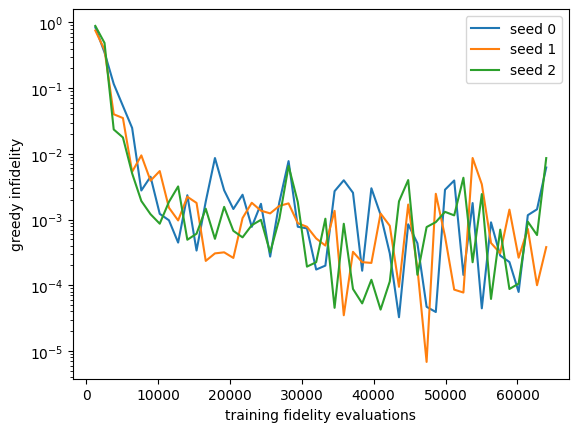

In [2]:
def train(seed,iters=1000,batch=64,shots=0):
    rng=np.random.default_rng(seed)
    mu=rng.normal(0,.2,(LAYERS,N));nu=np.full((LAYERS,N),np.log(.7))
    z=np.zeros((LAYERS-1,3));params=[mu,nu,z]
    first=[np.zeros_like(v) for v in params];second=[np.zeros_like(v) for v in params]
    logs=[]
    for it in range(1,iters+1):
        mu,nu,z=params;sig=np.exp(nu);prob=softmax(z)
        noise=rng.normal(size=(batch,LAYERS,N));angles=mu+sig*noise
        gates=np.stack([rng.choice(3,batch,p=prob[t]) for t in range(LAYERS-1)],axis=1)
        F=circuit(angles,gates)
        R=rng.binomial(shots,F)/shots if shots else F
        baseline=(R.sum()-R)/(batch-1);adv=R-baseline
        gradients=[np.mean(adv[:,None,None]*noise/sig,axis=0),
                   np.mean(adv[:,None,None]*(noise**2-1),axis=0),
                   np.mean(adv[:,None,None]*(np.eye(3)[gates]-prob),axis=0)]
        for k,g in enumerate(gradients):
            first[k]=.9*first[k]+.1*g;second[k]=.999*second[k]+.001*g*g
            params[k]+=0.025*(first[k]/(1-.9**it))/(np.sqrt(second[k]/(1-.999**it))+1e-8)
        params[1][:]=np.clip(params[1],-4,0)
        if it%20==0:
            greedy=circuit(params[0][None],params[2].argmax(-1)[None])[0]
            logs.append([it*batch,float(F.mean()),float(greedy)])
    return params,np.array(logs)
RUNS=[train(seed) for seed in range(3)]
for seed,(params,log) in enumerate(RUNS):
    plt.plot(log[:,0],1-log[:,2],label=f'seed {seed}')
    print('seed',seed,'greedy fidelity',log[-1,2],'sampled training batch mean',log[-1,1],
          'gate types',params[2].argmax(-1))
plt.yscale('log');plt.xlabel('training fidelity evaluations');plt.ylabel('greedy infidelity');plt.legend();plt.show()

All three seeds pass the threshold $F>0.99$, and all three choose gate type 2, CZ, on both bonds. The next cell checks how many entangling gates this template needs.

In [3]:
best={}
for label,types in [('no entangler',(0,0)),('one CNOT',(1,0)),('one CZ',(2,0)),('two CZ',(2,2))]:
    t=np.array(types)[None]
    best[label]=max(-minimize(lambda x:-circuit(x.reshape(1,LAYERS,N),t)[0],
                              np.random.default_rng(s).normal(size=LAYERS*N)).fun for s in range(10))
    print(f'{label:13s} best fidelity over 10 starts {best[label]:.12f}')
assert best['no entangler']<0.51 and best['one CZ']>0.999999

no entangler  best fidelity over 10 starts 0.500000000000
one CNOT      best fidelity over 10 starts 1.000000000000
one CZ        best fidelity over 10 starts 1.000000000000
two CZ        best fidelity over 10 starts 1.000000000000


Without an entangler the product states reach at most $F=1/2$. A single CNOT or CZ already reaches $F=1$. The two CZ gates chosen by every seed therefore reflect a reward without gate cost and supply no statement about efficient circuits.

## A reference and independent evaluation
The reference optimises six angles with both bond gates fixed to CNOT. Four starts establish a successful numerical candidate. One exact parameter-shift gradient requires twelve fidelity evaluations. The count below includes objective evaluations separately.

We evaluate each frozen stochastic policy on fresh samples, and its mean-angle circuit separately. We report standard errors for stochastic evaluation and individual training seeds.

In [4]:
references=[]
for seed in range(4):
    counts={'objective':0,'gradient_fidelities':0}
    def obj(x):counts['objective']+=1;return -template_f(x)
    def jac(x):counts['gradient_fidelities']+=2*x.size;return -shift_gradient(x)
    ref=minimize(obj,np.random.default_rng(seed+100).normal(size=6),jac=jac,method='BFGS',options={'maxiter':150})
    references.append({'seed':seed,'fidelity':float(-ref.fun),'fidelity_evaluations':sum(counts.values())})
print('Fixed-CNOT parameter-shift references:',references)
evaluation=[]
for seed,(params,log) in enumerate(RUNS):
    rng=np.random.default_rng(1000+seed);mu,nu,z=params;prob=softmax(z);b=4000
    angles=mu+np.exp(nu)*rng.normal(size=(b,LAYERS,N))
    gates=np.stack([rng.choice(3,b,p=prob[t]) for t in range(LAYERS-1)],1)
    F=circuit(angles,gates)
    entry={'seed':seed,'stochastic_mean':float(F.mean()),'stochastic_SE':float(F.std(ddof=1)/np.sqrt(b)),
           'greedy_fidelity':float(circuit(mu[None],z.argmax(-1)[None])[0]),
           'training_interactions':int(log[-1,0]),'evaluation_interactions':b+1,
           'greedy_two_qubit_gates':int(np.count_nonzero(z.argmax(-1)))}
    evaluation.append(entry);print(entry)
noisy_params,noisy_log=train(0,shots=100)
print('Separate seed-0 run with 100 shots per training reward; final exact greedy F:',noisy_log[-1,2])
summary={'target':'W2','rotation_layers':LAYERS,'training_seeds':evaluation,
         'reference_fixed_CNOT':references,'shot_run':{'seed':0,'shots':100,'greedy_fidelity':float(noisy_log[-1,2])},
         'runtime_seconds':time.perf_counter()-started}
(OUT/'lab059_results.json').write_text(json.dumps(summary,indent=2))
np.savez_compressed(OUT/'lab059_learning.npz',logs=np.array([log for _,log in RUNS]),shot_log=noisy_log)
print('Runtime seconds:',summary['runtime_seconds'])

Fixed-CNOT parameter-shift references: [{'seed': 0, 'fidelity': 0.9999999999464022, 'fidelity_evaluations': 143}, {'seed': 1, 'fidelity': 0.999999999990125, 'fidelity_evaluations': 130}, {'seed': 2, 'fidelity': 0.9999999999689788, 'fidelity_evaluations': 143}, {'seed': 3, 'fidelity': 0.9999999999932947, 'fidelity_evaluations': 130}]
{'seed': 0, 'stochastic_mean': 0.991476772617282, 'stochastic_SE': 0.00036610015623858875, 'greedy_fidelity': 0.9938002420256743, 'training_interactions': 64000, 'evaluation_interactions': 4001, 'greedy_two_qubit_gates': 2}
{'seed': 1, 'stochastic_mean': 0.9965202816347264, 'stochastic_SE': 0.00023907814279312565, 'greedy_fidelity': 0.9996192232059505, 'training_interactions': 64000, 'evaluation_interactions': 4001, 'greedy_two_qubit_gates': 2}
{'seed': 2, 'stochastic_mean': 0.9890666665210174, 'stochastic_SE': 0.0001544966088636463, 'greedy_fidelity': 0.9913783775154053, 'training_interactions': 64000, 'evaluation_interactions': 4001, 'greedy_two_qubit_gat

The fixed-CNOT reference reaches $F>0.9999999999$ with 130 to 143 fidelity evaluations and exact gradients. Each REINFORCE seed used 64,000 sampled fidelity evaluations and also had to choose the gates. These numbers belong to different tasks with different information. Over 4000 fresh samples the stochastic policies average 0.9915, 0.9965 and 0.9891, so seed 2 passes the threshold with its mean-angle circuit while its sampled circuits on average fall just below it.

The 100-shot run used $64{,}000\times100=6.4\times10^6$ measurement shots. Its greedy fidelity 0.99943 exceeds that of the exact-reward seed 0. This is a single run with a different random stream and supplies no evidence that shot noise helps.

## Student calculations
Differentiate the Gaussian log density while holding the sample fixed. Derive the categorical score and show its mean is zero. Explain why the leave-one-out baseline has zero expected score contribution. Compare the greedy fidelity with the independent stochastic mean and its standard error. Account separately for training circuits, evaluation circuits, parameter-shift evaluations and measurement shots. Repeat the comparison with CNOT fixed for the policy as well, to isolate the gate-choice difference.